# Pipeline de preprocesamiento sin data leakage (CICIDS-2017)
Proyecto Integrador I - QSVM para detección de intrusiones

**Orden de los pasos (importante, no cambiarlo):**
1. Cargar y limpiar (duplicadas, constantes, nulos/infinitos)
2. Analizar `Label` y binarizarla
3. Partición estratificada train / val / test
4. Eliminar features muy correlacionadas (calculado SOLO con train)
5. Submuestreo estratificado (para que el QSVM sea viable en simulación)
6. Escalado + PCA (ajustados SOLO con train)
7. Guardar resultados para SVM, Random Forest y QSVM

**Por qué el orden importa:** todo lo que "aprende" de los datos (correlaciones,
media/desviación del escalador, componentes del PCA) debe ajustarse solo con
train. Si se ajusta con todo el dataset, el modelo "ve" información del test
y las métricas salen infladas (data leakage).

In [1]:
import numpy as np
import pandas as pd
import optuna
import glob
import joblib
import time
import matplotlib.pyplot as plt
import optuna.visualization as vis
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.decomposition import PCA
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay, calibration_curve
from sklearn.metrics.pairwise import euclidean_distances
from scipy.stats import spearmanr

#Librerías para random forest
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    auc,
    roc_auc_score,
    f1_score,
    accuracy_score,
    roc_curve, 
    balanced_accuracy_score,
    average_precision_score,
    log_loss, 
    brier_score_loss
)

## 0. Configuración
Cambien aquí los parámetros; el resto del código no debería tocarse.

In [2]:

COL_LABEL = "Label"
CLASE_BENIGNA = "BENIGN"        # nombre exacto de la clase normal en su dataset

SEMILLA = 42                    # misma semilla para TODOS: reproducibilidad
UMBRAL_CORR = 0.95              # |r| mayor a esto => se elimina una de las dos
PROP_VAL, PROP_TEST = 0.15, 0.15

# Tamaños del subconjunto (el kernel cuántico necesita un circuito por cada
# par de muestras: costo ~ n^2). Empiecen pequeño y suban si hay tiempo.
N_TRAIN, N_VAL, N_TEST = 10000, 1000, 1000

N_COMPONENTES = 8               # = número de qubits del QSVM (prueben 4 y 8)
USAR_LOG = True                 # log-transform de colas pesadas antes de escalar
QUITAR_DUPLICADOS = True        # CICIDS-2017 tiene muchas filas repetidas

## 1. Carga y limpieza básica
- Se quitan espacios en los nombres de columnas (CICIDS los trae con espacios).
- Se elimina `Fwd Header Length.1` (idéntica a `Fwd Header Length`, ya comprobado).
- Se eliminan las columnas constantes (las 8 con un único valor).
- Los `inf` se convierten en NaN y se **eliminan las filas** con NaN. Son ~0.1%
  (flujos con Flow Duration = 0), así que perdemos muy poco y evitamos inventar
  valores con una media global, que filtraría información del test al train.

In [3]:
import glob

# 1. Cargar y concatenar todos los CSVs desde Kaggle
archivos_csv = sorted(glob.glob("/kaggle/input/cicids2017/*.csv"))

if len(archivos_csv) == 0:
    archivos_csv = sorted(glob.glob("/kaggle/input/**/*.csv", recursive=True))

print(f"Se encontraron {len(archivos_csv)} archivos CSV:")
for f in archivos_csv:
    print(" -", f)

lista_dfs = [pd.read_csv(f, low_memory=False) for f in archivos_csv]
df = pd.concat(lista_dfs, axis=0, ignore_index=True)

df.columns = df.columns.str.strip()
print("\nForma inicial:", df.shape)

# 1.1 Columna duplicada
if "Fwd Header Length.1" in df.columns:
    assert df["Fwd Header Length"].equals(df["Fwd Header Length.1"])
    df = df.drop(columns="Fwd Header Length.1")

# 1.2 Columnas constantes (sin varianza)
constantes = [c for c in df.columns if c != COL_LABEL and df[c].nunique(dropna=False) == 1]
print("Columnas constantes eliminadas:", constantes)
df = df.drop(columns=constantes)

# 1.3 Infinitos y nulos -> eliminar filas
df = df.replace([np.inf, -np.inf], np.nan)
n_antes = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Filas eliminadas por NaN/inf: {n_antes - len(df)} ({(n_antes - len(df)) / n_antes:.3%})")

# 1.4 Duplicados (opcional)
if QUITAR_DUPLICADOS:
    n_antes = len(df)
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Filas duplicadas eliminadas: {n_antes - len(df)}")

print("Forma tras limpieza:", df.shape)

Se encontraron 8 archivos CSV:
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
 - /kaggle/input/datasets/mdalamintalukder/cicids2017/MachineLearningCVE/Wednesday-workingHours.pcap_ISCX.csv

Forma inicial: (283

## 2. Análisis de `Label` y binarización
Aquí se ve el desbalance de clases. Como el objetivo del proyecto es
normal vs. ataque, se binariza: 0 = benigno, 1 = ataque. Se conserva el tipo
de ataque original en `Label_original` por si luego quieren analizar
sensibilidad a ataques poco frecuentes.

Label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

Proporción binaria (0=benigno, 1=ataque):
y
0    0.8311
1    0.1689
Name: proportion, dtype: float64


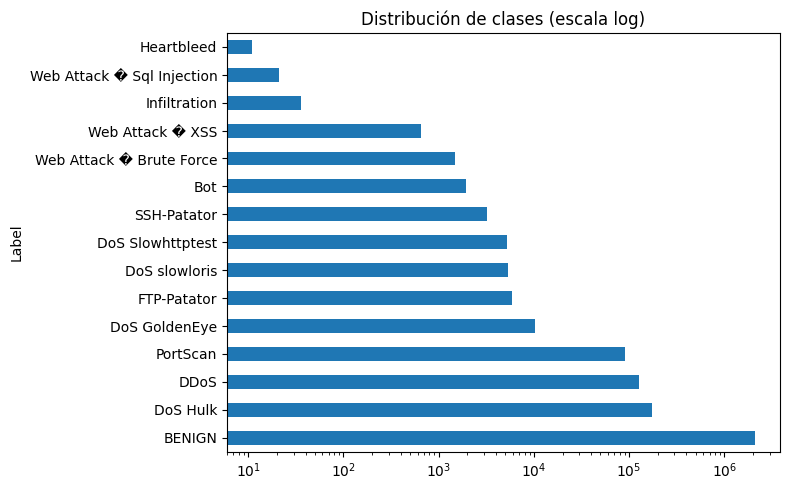

In [4]:
print(df[COL_LABEL].value_counts())

df["Label_original"] = df[COL_LABEL]
df["y"] = (df[COL_LABEL] != CLASE_BENIGNA).astype(int)

print("\nProporción binaria (0=benigno, 1=ataque):")
print(df["y"].value_counts(normalize=True).round(4))

df[COL_LABEL].value_counts().plot(kind="barh", logx=True, figsize=(8, 5),
                                  title="Distribución de clases (escala log)")
plt.tight_layout(); plt.show()

## 3. Partición estratificada train / val / test
`stratify=y` mantiene la misma proporción de ataques en los tres conjuntos.
**Se divide ANTES de cualquier ajuste** (correlación, escalado, PCA).

In [5]:
features = [c for c in df.columns if c not in (COL_LABEL, "Label_original", "y")]

X = df[features]
y = df["y"]
etiquetas_orig = df["Label_original"]

X_tmp, X_test, y_tmp, y_test, lab_tmp, lab_test = train_test_split(
    X, y, etiquetas_orig, test_size=PROP_TEST, stratify=y, random_state=SEMILLA)

rel_val = PROP_VAL / (1 - PROP_TEST)
X_train, X_val, y_train, y_val, lab_train, lab_val = train_test_split(
    X_tmp, y_tmp, lab_tmp, test_size=rel_val, stratify=y_tmp, random_state=SEMILLA)

for nombre, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{nombre}: {len(yy):>9,} filas | % ataque = {yy.mean():.3f}")

train: 1,764,558 filas | % ataque = 0.169
val:   378,120 filas | % ataque = 0.169
test:   378,120 filas | % ataque = 0.169


## 4. Eliminación de features correlacionadas (solo con train)
Para cada par con |r| > UMBRAL_CORR se elimina una de las dos columnas.
Se usa una muestra de train para que sea rápido con millones de filas.

In [6]:
muestra_corr = X_train.sample(n=min(200_000, len(X_train)), random_state=SEMILLA)
corr = muestra_corr.corr(method="pearson").abs()

# Triángulo superior: cada par se revisa una sola vez
triangulo = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
a_eliminar = [c for c in triangulo.columns if (triangulo[c] > UMBRAL_CORR).any()]

print(f"Features eliminadas por correlación > {UMBRAL_CORR}: {len(a_eliminar)}")
for c in a_eliminar:
    par = triangulo[c][triangulo[c] > UMBRAL_CORR].idxmax()
    print(f"  - {c:35s} (correlacionada con {par}: {triangulo.loc[par, c]:.3f})")

features_finales = [c for c in features if c not in a_eliminar]
print(f"\nFeatures que quedan: {len(features_finales)} de {len(features)}")

X_train, X_val, X_test = (d[features_finales] for d in (X_train, X_val, X_test))

Features eliminadas por correlación > 0.95: 23
  - Total Backward Packets              (correlacionada con Total Fwd Packets: 1.000)
  - Total Length of Bwd Packets         (correlacionada con Total Fwd Packets: 1.000)
  - Fwd Packet Length Std               (correlacionada con Fwd Packet Length Max: 0.971)
  - Bwd Packet Length Mean              (correlacionada con Bwd Packet Length Max: 0.958)
  - Bwd Packet Length Std               (correlacionada con Bwd Packet Length Max: 0.982)
  - Fwd IAT Total                       (correlacionada con Flow Duration: 0.998)
  - Fwd IAT Max                         (correlacionada con Flow IAT Max: 0.998)
  - Fwd Packets/s                       (correlacionada con Flow Packets/s: 0.979)
  - Packet Length Std                   (correlacionada con Max Packet Length: 0.984)
  - SYN Flag Count                      (correlacionada con Fwd PSH Flags: 1.000)
  - CWE Flag Count                      (correlacionada con Fwd URG Flags: 1.000)
  - ECE Flag Co

## 5. Preprocesamiento: log + escalado + PCA (ajustar SOLO con train)
- **Log firmado:** las features de red tienen colas enormes (duraciones, bytes).
  Sin esto, unos pocos outliers dominan el PCA. Se usa `sign(x)*log1p(|x|)`
  porque algunas columnas tienen valores negativos.
- **StandardScaler:** media 0, desviación 1 (requisito previo del PCA).
- **PCA:** reduce a `N_COMPONENTES` (= qubits).
- **MinMaxScaler a [0, pi]:** los feature maps cuánticos codifican los datos
  como ángulos de rotación, por eso se lleva la salida del PCA a ese rango.

Varianza explicada acumulada: [0.42  0.561 0.639 0.689 0.731 0.768 0.798 0.825]


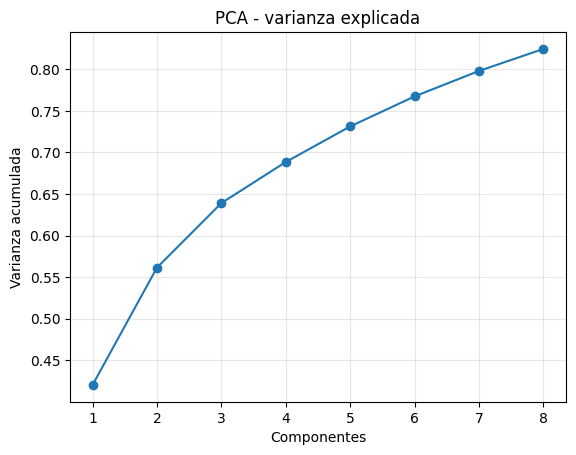

In [7]:
def log_firmado(a):
    """Log que soporta valores negativos y ceros."""
    a = np.asarray(a, dtype=float)
    return np.sign(a) * np.log1p(np.abs(a))

def transformar_previo(d):
    a = d.values.astype(float)
    return log_firmado(a) if USAR_LOG else a

scaler = StandardScaler().fit(transformar_previo(X_train))
pca = PCA(n_components=N_COMPONENTES, random_state=SEMILLA)
pca.fit(scaler.transform(transformar_previo(X_train)))

def a_pca(d):
    return pca.transform(scaler.transform(transformar_previo(d)))

Z_train, Z_val, Z_test = a_pca(X_train), a_pca(X_val), a_pca(X_test)

var_acum = pca.explained_variance_ratio_.cumsum()
print("Varianza explicada acumulada:", np.round(var_acum, 3))

plt.plot(range(1, N_COMPONENTES + 1), var_acum, marker="o")
plt.xlabel("Componentes"); plt.ylabel("Varianza acumulada")
plt.title("PCA - varianza explicada"); plt.grid(alpha=.3); plt.show()

# Escala a [0, pi] para el feature map cuántico (ajustada con train)
ang = MinMaxScaler(feature_range=(0, np.pi)).fit(Z_train)
def a_angulos(Z):
    return np.clip(ang.transform(Z), 0, np.pi)  # clip: val/test pueden salirse un poco

## 6. Submuestreo estratificado (para QSVM)
Se toma un subconjunto **de cada partición** ya transformada. Los tres modelos
(SVM, Random Forest, QSVM) usan EXACTAMENTE este subconjunto, así la
comparación es justa. Los índices se guardan para poder reproducirlo.

In [8]:
def submuestra(Z, y, lab, n, semilla):
    """Devuelve n filas conservando la proporción de clases."""
    if n >= len(y):
        idx = np.arange(len(y))
    else:
        idx, _ = train_test_split(np.arange(len(y)), train_size=n,
                                  stratify=y, random_state=semilla)
    return Z[idx], y.values[idx], lab.values[idx], idx

Zs_train, ys_train, ls_train, i_train = submuestra(Z_train, y_train, lab_train, N_TRAIN, SEMILLA)
Zs_val,   ys_val,   ls_val,   i_val   = submuestra(Z_val,   y_val,   lab_val,   N_VAL,   SEMILLA)
Zs_test,  ys_test,  ls_test,  i_test  = submuestra(Z_test,  y_test,  lab_test,  N_TEST,  SEMILLA)

for nombre, yy in [("train", ys_train), ("val", ys_val), ("test", ys_test)]:
    print(f"{nombre}: {len(yy):>5} filas | % ataque = {yy.mean():.3f}")

train: 10000 filas | % ataque = 0.169
val:  1000 filas | % ataque = 0.169
test:  1000 filas | % ataque = 0.169


## 7. Guardar resultados
- `datos_subconjunto.npz`: lo que se carga en los notebooks de modelos.
  - `X_*`   -> salida del PCA (para SVM RBF y Random Forest)
  - `Xq_*`  -> misma salida escalada a [0, pi] (para el QSVM)
  - `y_*`   -> 0 benigno / 1 ataque
  - `lab_*` -> tipo de ataque original
- `transformadores.joblib`: scaler, PCA y demás, por si hay que transformar
  datos nuevos.

In [9]:
np.savez_compressed(
    "datos_subconjunto.npz",
    X_train=Zs_train, X_val=Zs_val, X_test=Zs_test,
    Xq_train=a_angulos(Zs_train), Xq_val=a_angulos(Zs_val), Xq_test=a_angulos(Zs_test),
    y_train=ys_train, y_val=ys_val, y_test=ys_test,
    lab_train=ls_train, lab_val=ls_val, lab_test=ls_test,
    idx_train=i_train, idx_val=i_val, idx_test=i_test,
)
joblib.dump({"scaler": scaler, "pca": pca, "ang": ang,
             "features": features_finales, "usar_log": USAR_LOG},
            "transformadores.joblib")
print("Guardado: datos_subconjunto.npz y transformadores.joblib")

Guardado: datos_subconjunto.npz y transformadores.joblib


## Cómo usar la salida en los notebooks de modelos
```python
import numpy as np
d = np.load("datos_subconjunto.npz", allow_pickle=True)
X_train, y_train = d["X_train"], d["y_train"]     # SVM / Random Forest
Xq_train = d["Xq_train"]                          # QSVM (ángulos en [0, pi])
```

# Modelo SVM clásico (kernel RBF)

Línea base clásica directa del QSVM: la única diferencia es el kernel (RBF en lugar del kernel cuántico).

Este modelo usa exactamente el mismo subconjunto que usará el QSVM: la salida del PCA (8 componentes) con 1,000 muestras de train, 300 de validación y 300 de test (`datos_subconjunto.npz`). Así la comparación SVM vs. QSVM es justa (Principio 1 de la documentación).

- Los hiperparámetros `C` y `gamma` se eligen solo con validación.
- El test se usa una sola vez, con el modelo final.
- Métricas: precisión, recall, F1, AUPRC, ROC-AUC, FPR, tiempo de entrenamiento e inferencia.

## 0. Carga del subconjunto común (SVM / QSVM)

In [10]:
from sklearn.metrics import precision_score, recall_score
import time
from sklearn.svm import SVC

# Se carga desde el .npz para garantizar que es el mismo subconjunto que usa el QSVM
# (y para no pisar X_train / y_train, que el Random Forest usa con las 46 variables).
d = np.load("datos_subconjunto.npz", allow_pickle=True)

Xs_train, ys_train = d["X_train"], d["y_train"]     # salida del PCA (NO los ángulos Xq_*)
Xs_val,   ys_val   = d["X_val"],   d["y_val"]
Xs_test,  ys_test  = d["X_test"],  d["y_test"]
ls_test = d["lab_test"]                             # tipo de ataque original (para análisis posterior)

for nombre, XX, yy in [("train", Xs_train, ys_train), ("val", Xs_val, ys_val), ("test", Xs_test, ys_test)]:
    print(f"{nombre}: X = {XX.shape} | % ataque = {yy.mean():.3f}")

train: X = (10000, 8) | % ataque = 0.169
val: X = (1000, 8) | % ataque = 0.169
test: X = (1000, 8) | % ataque = 0.169


## 1. GridSearchCV sobre validación

Mismo esquema que el Random Forest: `PredefinedSplit` para que entrene en train y evalúe solo en validación (sin validación cruzada, sin tocar el test). Se usa `f1` como criterio, igual que en el Random Forest, y `class_weight="balanced"` por el ~17 % de ataques.

Se guardan también las puntuaciones de train (`return_train_score=True`) para vigilar el sobreajuste: un `C` y un `gamma` muy altos memorizan train y caen en validación.

In [11]:
X_eval_svm = np.vstack([Xs_train, Xs_val])
y_eval_svm = np.concatenate([ys_train, ys_val])

# -1 = fila de entrenamiento, 0 = fila de validación
split_svm = [-1] * len(Xs_train) + [0] * len(Xs_val)
ps_svm = PredefinedSplit(test_fold=split_svm)

param_grid_svm = {
    "C":     [0.1, 1, 10, 100, 1000],
    "gamma": ["scale", 0.001, 0.01, 0.1, 1],
}

svm_base = SVC(kernel="rbf", class_weight="balanced", random_state=42)

grid_svm = GridSearchCV(
    estimator=svm_base,
    param_grid=param_grid_svm,
    scoring="f1",
    cv=ps_svm,
    n_jobs=-1,
    refit=False,               # el modelo final se entrena aparte, solo con train
    return_train_score=True,
)

print("Buscando C y gamma con GridSearchCV sobre validación...")
grid_svm.fit(X_eval_svm, y_eval_svm)

print("\n" + "=" * 60)
print("MEJORES HIPERPARÁMETROS ENCONTRADOS (SVM RBF):")
print(grid_svm.best_params_)
print("=" * 60)

# Tabla de resultados y chequeo de sobreajuste (train vs validación)
res_svm = (pd.DataFrame(grid_svm.cv_results_)
           [["param_C", "param_gamma", "mean_train_score", "mean_test_score"]]
           .rename(columns={"mean_train_score": "F1 train", "mean_test_score": "F1 val"}))
res_svm["brecha"] = res_svm["F1 train"] - res_svm["F1 val"]
print("\nTop 5 configuraciones por F1 en validación:")
print(res_svm.sort_values("F1 val", ascending=False).head(5).round(4).to_string(index=False))

Buscando C y gamma con GridSearchCV sobre validación...

MEJORES HIPERPARÁMETROS ENCONTRADOS (SVM RBF):
{'C': 10, 'gamma': 1}

Top 5 configuraciones por F1 en validación:
 param_C param_gamma  F1 train  F1 val  brecha
    10.0           1    0.9932  0.9912  0.0021
  1000.0         0.1    0.9926  0.9912  0.0015
   100.0           1    0.9947  0.9882  0.0065
  1000.0           1    0.9962  0.9882  0.0079
   100.0         0.1    0.9903  0.9796  0.0107


## 2. Entrenar el modelo final (solo con train)

In [12]:
svm_final = SVC(
    kernel="rbf",
    **grid_svm.best_params_,
    class_weight="balanced",
    random_state=42,
)

print(f"Entrenando SVM final con Xs_train ({len(Xs_train):,} filas)...")
t0 = time.perf_counter()
svm_final.fit(Xs_train, ys_train)
t_train_svm = time.perf_counter() - t0

print(f"Tiempo de entrenamiento: {t_train_svm:.3f} s")
print(f"Vectores de soporte: {svm_final.n_support_.sum()} de {len(Xs_train)}")

Entrenando SVM final con Xs_train (10,000 filas)...
Tiempo de entrenamiento: 0.568 s
Vectores de soporte: 1435 de 10000


## 3. Evaluación final en test (una sola vez)

In [13]:
t0 = time.perf_counter()
y_pred_svm = svm_final.predict(Xs_test)
scores_svm = svm_final.decision_function(Xs_test)   # puntaje continuo (mayor = más probable ataque)
t_inf_svm = time.perf_counter() - t0

tn, fp, fn, tp = confusion_matrix(ys_test, y_pred_svm).ravel()
fpr_svm = fp / (fp + tn)

prec_c, rec_c, _ = precision_recall_curve(ys_test, scores_svm)
auprc_svm   = auc(rec_c, prec_c)
roc_auc_svm = roc_auc_score(ys_test, scores_svm)
f1_svm      = f1_score(ys_test, y_pred_svm)
prec_svm    = precision_score(ys_test, y_pred_svm)
rec_svm     = recall_score(ys_test, y_pred_svm)

print("=" * 60)
print("RESULTADOS FINALES EN CONJUNTO DE TEST - SVM (RBF)")
print("=" * 60)
print(f"Precisión:                      {prec_svm:.4f}")
print(f"Recall:                         {rec_svm:.4f}")
print(f"F1-Score:                       {f1_svm:.4f}")
print(f"AUPRC (Precision-Recall AUC):   {auprc_svm:.4f}")
print(f"ROC-AUC:                        {roc_auc_svm:.4f}")
print(f"Tasa de Falsos Positivos (FPR): {fpr_svm:.4f} ({fpr_svm:.2%})")
print(f"Tiempo de entrenamiento:        {t_train_svm:.3f} s")
print(f"Tiempo de inferencia (test):    {t_inf_svm:.3f} s\n")

print("Reporte de clasificación detallado:")
print(classification_report(ys_test, y_pred_svm, target_names=["Benigno (0)", "Ataque (1)"]))

RESULTADOS FINALES EN CONJUNTO DE TEST - SVM (RBF)
Precisión:                      0.9765
Recall:                         0.9822
F1-Score:                       0.9794
AUPRC (Precision-Recall AUC):   0.9826
ROC-AUC:                        0.9925
Tasa de Falsos Positivos (FPR): 0.0048 (0.48%)
Tiempo de entrenamiento:        0.568 s
Tiempo de inferencia (test):    0.115 s

Reporte de clasificación detallado:
              precision    recall  f1-score   support

 Benigno (0)       1.00      1.00      1.00       831
  Ataque (1)       0.98      0.98      0.98       169

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



## 4. Matriz de confusión

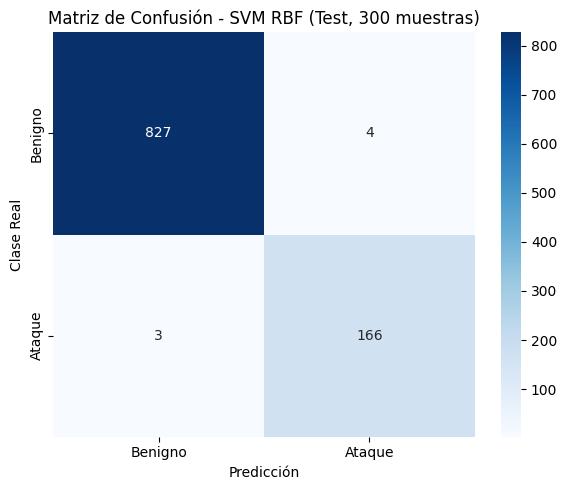

In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(ys_test, y_pred_svm),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benigno", "Ataque"],
    yticklabels=["Benigno", "Ataque"],
)
plt.title("Matriz de Confusión - SVM RBF (Test, 300 muestras)")
plt.xlabel("Predicción")
plt.ylabel("Clase Real")
plt.tight_layout()
plt.show()

## 5. Resumen para la matriz de resultados 

Fila lista para copiar a la tabla comparativa. Con solo 300 muestras de test (~250 benignas), un falso positivo mueve el FPR ≈ 0.4 puntos porcentuales, así que estas cifras deben interpretarse con cuidado.

In [15]:
resumen_svm = pd.DataFrame([{
    "Modelo": "SVM (RBF)",
    "Hiperparámetros": str(grid_svm.best_params_),
    "Precisión": round(prec_svm, 4),
    "Recall": round(rec_svm, 4),
    "F1": round(f1_svm, 4),
    "AUPRC": round(auprc_svm, 4),
    "FPR": round(fpr_svm, 4),
    "T. entrenamiento (s)": round(t_train_svm, 3),
    "T. inferencia (s)": round(t_inf_svm, 3),
}])
display(resumen_svm)

,Modelo,Hiperparámetros,Precisión,Recall,F1,AUPRC,FPR,T. entrenamiento (s),T. inferencia (s)
0,SVM (RBF),"{'C': 10, 'gamma': 1}",0.9765,0.9822,0.9794,0.9826,0.0048,0.568,0.115


# Modelo Random Forest

##  0. VERIFICACIÓN DE VARIABLES Y DIMENSIONES

In [16]:
print("Valores únicos en y_train:", np.unique(y_train))
print("Valores únicos en y_val:  ", np.unique(y_val))
print("Valores únicos en y_test: ", np.unique(y_test))

Valores únicos en y_train: [0 1]
Valores únicos en y_val:   [0 1]
Valores únicos en y_test:  [0 1]


In [17]:
# X_train, X_val y X_test contienen las 46 características tabulares limpias
# y_train, y_val y y_test contienen las etiquetas binarias (0 = BENIGN, 1 = Ataque)

print(f"Número de características para Random Forest: {X_train.shape[1]}")
print(f"Muestras de entrenamiento (Train):          {X_train.shape[0]}")
print(f"Muestras de prueba (Test):                 {X_test.shape[0]}")

Número de características para Random Forest: 46
Muestras de entrenamiento (Train):          1764558
Muestras de prueba (Test):                 378120


##  1. PREPARAR MUESTRA RÁPIDA DE TRAIN + CONJUNTO DE VAL

Se hace una reducción para coincidir con el modelo cuántico

In [18]:
# 1. Tomamos las muestras reducidas de los conjuntos que ya tenías
X_tr_fast = X_train.sample(n=min(N_TRAIN, len(X_train)), random_state=42)
y_tr_fast = y_train.loc[X_tr_fast.index]

X_val_fast = X_val.sample(n=min(N_VAL, len(X_val)), random_state=42)
y_val_fast = y_val.loc[X_val_fast.index]

X_test_fast = X_test.sample(n=min(N_TEST, len(X_test)), random_state=42)
y_test_fast = y_test.loc[X_test_fast.index]

# 2. Unimos únicamente las muestras reducidas de Train y Val
X_eval = pd.concat([X_tr_fast, X_val_fast])
y_eval = pd.concat([y_tr_fast, y_val_fast])

# 3. Mantenemos el mismo aislante de PredefinedSplit
split_index = [-1] * len(X_tr_fast) + [0] * len(X_val_fast)
ps = PredefinedSplit(test_fold=split_index)

## 2. GRIDSEARCHCV

In [19]:
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [8, 12, 16],
    'criterion': ['gini', 'entropy']
}

rf_base = RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1)

# GridSearchCV usará estrictamente X_val para evaluar cada combinación
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    scoring='f1',
    cv=ps,        # <--- Le indica usar X_val como conjunto de validación fijado
    n_jobs=-1
)

print("Buscando hiperparámetros con GridSearchCV sobre X_val...")
grid_search.fit(X_eval, y_eval)

print("\n" + "="*60)
print("MEJORES HIPERPARÁMETROS ENCONTRADOS:")
print(grid_search.best_params_)
print("="*60)

Buscando hiperparámetros con GridSearchCV sobre X_val...

MEJORES HIPERPARÁMETROS ENCONTRADOS:
{'criterion': 'gini', 'max_depth': 12, 'n_estimators': 100}


## 3. ENTRENAR MODELO FINAL EN TODO TRAIN 

In [20]:
print(f"\nEntrenando modelo final con todo X_train ({len(X_tr_fast):,} filas)...")
rf_final = RandomForestClassifier(
    **grid_search.best_params_,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_final.fit(X_tr_fast,  y_tr_fast)


Entrenando modelo final con todo X_train (10,000 filas)...


RandomForestClassifier(class_weight='balanced', max_depth=12, n_jobs=-1,
                       random_state=42)

## 4. EVALUACIÓN FINAL EN TEST (Métricas del anteproyecto)

In [21]:
# Evaluar sobre la muestra reducida de test (1,000 registros)
y_pred_test = rf_final.predict(X_test_fast)
y_probs_test = rf_final.predict_proba(X_test_fast)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_test_fast, y_pred_test).ravel()
fpr = fp / (fp + tn)

precision, recall, _ = precision_recall_curve(y_test_fast, y_probs_test)
auprc = auc(recall, precision)
roc_auc = roc_auc_score(y_test_fast, y_probs_test)
f1 = f1_score(y_test_fast, y_pred_test)

print("\n" + "="*60)
print("RESULTADOS FINALES EN CONJUNTO DE TEST")
print("="*60)
print(f"AUPRC (Precision-Recall AUC): {auprc:.4f}")
print(f"ROC-AUC:                        {roc_auc:.4f}")
print(f"Tasa de Falsos Positivos (FPR): {fpr:.4f} ({fpr:.2%})")
print(f"F1-Score:                       {f1:.4f}\n")

print("Reporte de clasificación detallado:")
print(classification_report(y_test_fast, y_pred_test, target_names=["Benigno (0)", "Ataque (1)"]))


RESULTADOS FINALES EN CONJUNTO DE TEST
AUPRC (Precision-Recall AUC): 1.0000
ROC-AUC:                        1.0000
Tasa de Falsos Positivos (FPR): 0.0000 (0.00%)
F1-Score:                       0.9971

Reporte de clasificación detallado:
              precision    recall  f1-score   support

 Benigno (0)       1.00      1.00      1.00       828
  Ataque (1)       1.00      0.99      1.00       172

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



##  5. MATRIZ DE CONFUSIÓN

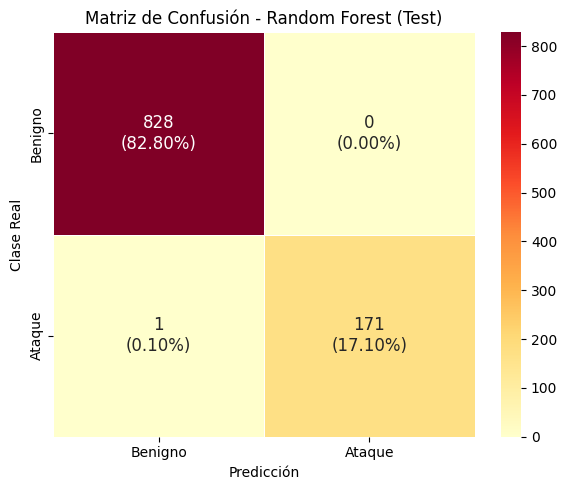

In [22]:
cm_rf = confusion_matrix(y_test_fast, y_pred_test)

tn, fp, fn, tp = cm_rf.ravel()
total = cm_rf.sum()
tp_percent = (tp / total) * 100
fp_percent = (fp / total) * 100
tn_percent = (tn / total) * 100
fn_percent = (fn / total) * 100

labels = [
    [f"{cm_rf[0,0]}\n({tn_percent:.2f}%)", f"{cm_rf[0,1]}\n({fp_percent:.2f}%)"],
    [f"{cm_rf[1,0]}\n({fn_percent:.2f}%)", f"{cm_rf[1,1]}\n({tp_percent:.2f}%)"]
]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=labels,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    annot_kws={"size": 12},
    xticklabels=["Benigno", "Ataque"],
    yticklabels=["Benigno", "Ataque"]
)

plt.title("Matriz de Confusión - Random Forest (Test)")
plt.xlabel("Predicción")
plt.ylabel("Clase Real")
plt.tight_layout()
plt.show()

## 6. Reporte

### Análisis del Modelo Baseline (Random Forest Binario)

Para definir nuestra línea base (*baseline*) alineada con la escala del modelo cuántico, entrenamos el Random Forest binario utilizando una muestra acotada de 10,000 filas de `Train`. Los hiperparámetros se optimizaron evaluando sobre una muestra fija de `Validation` (1,000 filas) mediante `PredefinedSplit`, manteniendo el conjunto de `Test` (1,000 filas) totalmente aislado para la evaluación final.

#### Resultados en el Conjunto de Test
Evaluando sobre el conjunto de prueba independiente (`Test` con 1,000 muestras), se obtuvieron las siguientes métricas:

* **AUPRC (Precision-Recall AUC):** 1.0000
* **ROC-AUC:** 1.0000
* **F1-Score Global:** 0.9971
* **Tasa de Falsos Positivos (FPR):** 0.00%

#### Interpretación de la Matriz de Confusión
Al revisar el desglose exacto de predicciones sobre las 1,000 muestras de prueba:
* **Verdaderos Negativos (TN)**: 828 conexiones benignas correctamente clasificadas.
* **Falsos Positivos (FP)**: De 828 conexiones benignas reales, el modelo no clasificó erróneamente ninguna como ataque.
* **Falsos Negativos (FN):** De 172 ataques reales, el modelo únicamente dejó pasar 1 como tráfico normal.
* **Verdaderos Positivos (TP)**: 171 ataques detectados exitosamente.

En total, el algoritmo solo cometió **1 error sobre 1,000 registros**, lo que representa una tasa global de error de apenas el **0.10%**. La razón por la que en el reporte de Python aparecen valores de `1.00` en Precision para la clase Ataque y `0.99` en Recall y F1-Score se debe al redondeo a dos decimales, pero las métricas exactas confirman que el modelo mantiene un desempeño sumamente alto y preciso.

#### Discusión Crítica
El hecho de que el modelo alcance un rendimiento casi perfecto reduciendo el volumen de entrenamiento de 1.76 millones a solo 10,000 filas confirma la alta separabilidad del dataset en el dominio clásico, pero también levanta alertas sobre posible **fuga de información (data leakage)** o atajos de memorización:

* **Memorización de atajos**: Es muy probable que existan variables con alta capacidad predictiva directa (como ciertos puertos, flags TCP específicos o rangos fijos de tiempo de respuesta) que permiten al árbol clasificar sin necesidad de aprender patrones complejos de comportamiento.
* **Aplicación en entornos reales**: Si el objetivo es comparar de forma justa este baseline con la SVM Cuántica (QSVM), es imprescindible verificar que ninguna característica del dataset contenga información "del futuro" o identificadores estáticos que faciliten artificialmente la tarea a ambos algoritmos.

#### Conclusión
Este Random Forest ajustado cumple su función como **modelo baseline a escala acotada**. Confirma que la muestra reducida retiene la estructura del dataset original y fija la meta de rendimiento máximo para evaluar si la SVM Cuántica (QSVM) logra ser competitiva bajo un espacio de características igualmente restringido.

## Verificación de fuga de información

### PASO 1: CÁLCULO Y VISUALIZACIÓN DE IMPORTANCIA DE CARACTERÍSTICAS

TOP 10 CARACTERÍSTICAS MÁS IMPORTANTES EN RANDOM FOREST
             Característica  Importancia
     Packet Length Variance     0.104404
      Bwd Packet Length Max     0.083427
           Destination Port     0.073143
          Max Packet Length     0.063386
         Packet Length Mean     0.056978
      Fwd Packet Length Max     0.052017
    Init_Win_bytes_backward     0.050286
Total Length of Fwd Packets     0.039622
     Fwd Packet Length Mean     0.032543
      Bwd Packet Length Min     0.030663


/tmp/ipykernel_23/1468793103.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


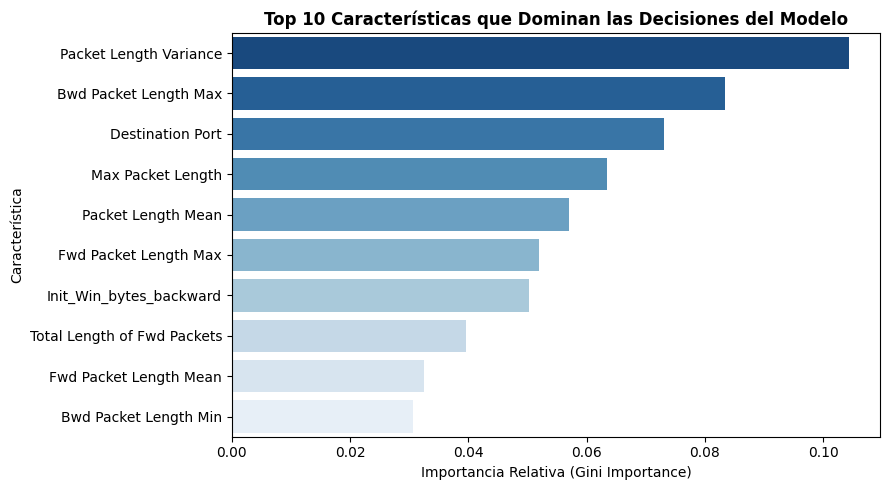

In [23]:
# Usamos rf_final que es la variable que entrenaste
importances = rf_final.feature_importances_
feature_names = X_tr_fast.columns

# Crear DataFrame ordenado
df_importance = (
    pd.DataFrame({'Característica': feature_names, 'Importancia': importances})
    .sort_values(by='Importancia', ascending=False)
    .reset_index(drop=True)
)

print("="*60)
print("TOP 10 CARACTERÍSTICAS MÁS IMPORTANTES EN RANDOM FOREST")
print("="*60)
print(df_importance.head(10).to_string(index=False))
print("="*60)

# Graficar
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df_importance.head(10),
    x='Importancia',
    y='Característica',
    palette='Blues_r'
)
plt.title("Top 10 Características que Dominan las Decisiones del Modelo", fontsize=12, fontweight='bold')
plt.xlabel("Importancia Relativa (Gini Importance)")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

### 2. EXPERIMENTO SIN VARIABLES DE FUGA (REENTRENAMIENTO LIMPIO)

In [24]:
# Mantenemos todas las variables físicas/estadísticas y eliminamos SOLO identificadores fijos
cols_to_drop = [
    col for col in ['Destination Port', 'Source Port', 'Port', 'Flow ID', 'Source IP', 'Destination IP', 'Timestamp']
    if col in X_tr_fast.columns
]

print(f"Variables retiradas por riesgo de fuga/memorización: {cols_to_drop}")

# Crear conjuntos limpios
X_tr_clean = X_tr_fast.drop(columns=cols_to_drop)
X_test_clean = X_test_fast.drop(columns=cols_to_drop)

# Reentrenar con los hiperparámetros óptimos que ya encontraste
rf_clean = RandomForestClassifier(
    **grid_search.best_params_,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_clean.fit(X_tr_clean, y_tr_fast)


y_pred_clean = rf_clean.predict(X_test_clean)
f1_clean = f1_score(y_test_fast, y_pred_clean)

print("\n" + "="*60)
print("EVALUACIÓN DEL MODELO LIMPIO (SIN IDENTIFICADORES ESTÁTICOS)")
print("="*60)
print(f"F1-Score en Test: {f1_clean:.4f}\n")
print(classification_report(y_test_fast, y_pred_clean, target_names=["Benigno (0)", "Ataque (1)"]))

Variables retiradas por riesgo de fuga/memorización: ['Destination Port']

EVALUACIÓN DEL MODELO LIMPIO (SIN IDENTIFICADORES ESTÁTICOS)
F1-Score en Test: 0.9913

              precision    recall  f1-score   support

 Benigno (0)       1.00      1.00      1.00       828
  Ataque (1)       0.99      0.99      0.99       172

    accuracy                           1.00      1000
   macro avg       0.99      1.00      0.99      1000
weighted avg       1.00      1.00      1.00      1000



### Reporte

####  Análisis del Modelo Baseline Limpio (Random Forest Binario)

Para validar rigurosamente la ausencia de data leakage o memorización de atajos, se reentrenó el algoritmo Random Forest retirando identificadores estáticos de red (`Destination Port`). El entrenamiento se realizó con la muestra de 10,000 datos de `Train` y la evaluación final sobre los 1,000 datos independientes de `Test`.

#### Resultados en el Conjunto de Test (Modelo Limpio)

Evaluando sobre la muestra de prueba libre de identificadores estáticos, se obtuvieron las siguientes métricas:

* F1-Score Global: 0.9913
* Precision (Ataque): 0.99
* Recall (Ataque): 0.99
* Accuracy Global: 1.00

#### Discusión y Validación de Fuga de Datos

La comparación directa entre el modelo con puertos (F1=0.9971) y el modelo sin identificadores estáticos (F1=0.9913) demuestra que la ligera reducción del rendimiento es marginal.

Esto confirma metodológicamente que:

* **Ausencia de fuga por atajos**: El modelo no dependía exclusivamente del puerto de destino para tomar decisiones acertadas.
* **Separabilidad comportamental**: Las variables estadísticas de la física del flujo (`Packet Length Variance`, `Bwd Packet Length Max`, etc.) poseen suficiente poder discriminativo para separar el tráfico benigno del ataques en el dominio clásico.

#### Conclusión

Se valida satisfactoriamente la robustez del **Random Forest como modelo baseline**. Queda establecido que el problema presenta una alta separabilidad en el espacio clásico utilizando métricas dinámicas de red, dejando definida la meta de rendimiento a comparar frente al pipeline de la SVM Cuántica (QSVM).

# Modelo Quantum Support Vector Machine (QSVM)

In [25]:
!pip install qiskit qiskit_machine_learning pylatexenc optuna qiskit-aer-gpu-cu11

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 52.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 282.3/282.3 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.1/18.1 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.6/38.6 MB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 417.9/417.9 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 875.6/875.6 kB 35.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.2/128.2 MB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.1/204.1 MB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.1/

In [26]:
# Librerias para QSVM
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit.circuit.library import zz_feature_map
from sklearn.svm import SVC
from qiskit import QuantumCircuit
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

##  0. Cargado de datos y verificación de dimensiones

In [27]:
d = np.load("datos_subconjunto.npz", allow_pickle=True)
Xq_train, Xq_val, Xq_test = d["Xq_train"], d["Xq_val"], d["Xq_test"]
y_train, y_val, y_test = d["y_train"], d["y_val"], d["y_test"] 
print(f"Número de características: {Xq_train.shape[1]}")
print(f"Muestras de entrenamiento (Xq_train): {Xq_train.shape[0]}")
print(f"Muestras de prueba (Xq_test): {Xq_test.shape[0]}")

Número de características: 8
Muestras de entrenamiento (Xq_train): 10000
Muestras de prueba (Xq_test): 1000


##  1. Iniciar el simulador cuantico AER, usando la GPU

In [28]:
aer_gpu = AerSimulator(method="statevector", device="GPU")
aer_gpu.set_options(cuStateVec_enable=True)

##  2. Busqueda de hiperparametros con Optuna

Usando Optuna se definen los hiperparametros a buscar como `C`, `reps` y `alpha`, se crea un kernel cuantico que contiene el feature map con los hiperparametros escogidos durante el trial para la configuracion del modelo, este modelo se entrena y prueba en el conjunto de validacion y se evaluan los resultados usando `f1` como criterio de evaluacion, igual que en los otros modelos, y se hace uso de `class_weight="balanced"` por la cantidad de ataques en los datos, que es mucho menor a los beningnos.

Se ejecutan 10 trials para encontrar el grupo de hiperparametros que da los mejores resultados, ademas de graficar los resultados obtenidos y datos de importancia obtenidos.

In [29]:
def objective(trial):
    C = trial.suggest_float(
        "C", 1e-1, 1e3, log=True
    )

    reps = trial.suggest_int("reps", 1, 3)

    alpha = trial.suggest_float("alpha", 0.5, 3)

    trial_feature_map = zz_feature_map(
        feature_dimension=8,
        reps=reps,
        entanglement="linear",
        alpha=alpha
    )

    trial_quantum_kernel = FidelityStatevectorKernel(
        feature_map=trial_feature_map,
        shots=None
    )

    K_train_trial = trial_quantum_kernel.evaluate(x_vec=Xq_train, y_vec=Xq_train)
    K_val_trial = trial_quantum_kernel.evaluate(x_vec=Xq_val, y_vec=Xq_train)

    model = SVC(
        kernel="precomputed",
        class_weight="balanced",
        C=C,
    )

    model.fit(K_train_trial, y_train)

    val_pred = model.predict(K_val_trial)

    return f1_score(
        y_val,
        val_pred,
        average="macro"
    )

In [30]:
study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=42)
)

study.optimize(
    objective,
    n_trials=10,
    n_jobs=1,
    show_progress_bar=True
)

print("\n \n Best validation macro-F1:", study.best_value)
print("Best hyperparameters:")
print(study.best_params)

[I 2026-11-04 18:27:28,616] A new study created in memory with name: no-name-1e142703-32de-4655-8581-fd3db027d9a6


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-04 18:44:51,624] Trial 0 finished with value: 0.991161689814201 and parameters: {'C': 3.14891164795686, 'reps': 3, 'alpha': 2.3299848545285125}. Best is trial 0 with value: 0.991161689814201.
[I 2026-11-04 19:00:53,377] Trial 1 finished with value: 0.9806457629176337 and parameters: {'C': 24.81040974867808, 'reps': 1, 'alpha': 0.8899863008405067}. Best is trial 0 with value: 0.991161689814201.
[I 2026-11-04 19:18:05,462] Trial 2 finished with value: 0.9805557175912423 and parameters: {'C': 0.17073967431528117, 'reps': 3, 'alpha': 2.002787529358022}. Best is trial 0 with value: 0.991161689814201.
[I 2026-11-04 19:33:52,387] Trial 3 finished with value: 0.9876836673112215 and parameters: {'C': 67.96578090758145, 'reps': 1, 'alpha': 2.9247746304049858}. Best is trial 0 with value: 0.991161689814201.
[I 2026-11-04 19:49:58,938] Trial 4 finished with value: 0.9876836673112215 and parameters: {'C': 213.6832907235874, 'reps': 1, 'alpha': 0.9545624180177515}. Best is trial 0 with va

##  3. Graficos de hiperparametros de Optuna

In [31]:
vis.plot_optimization_history(study).show()

In [32]:
vis.plot_param_importances(study).show()

In [33]:
vis.plot_parallel_coordinate(study).show()

##  4. Construccion de feature map

reps: 3
alpha: 2.3299848545285125


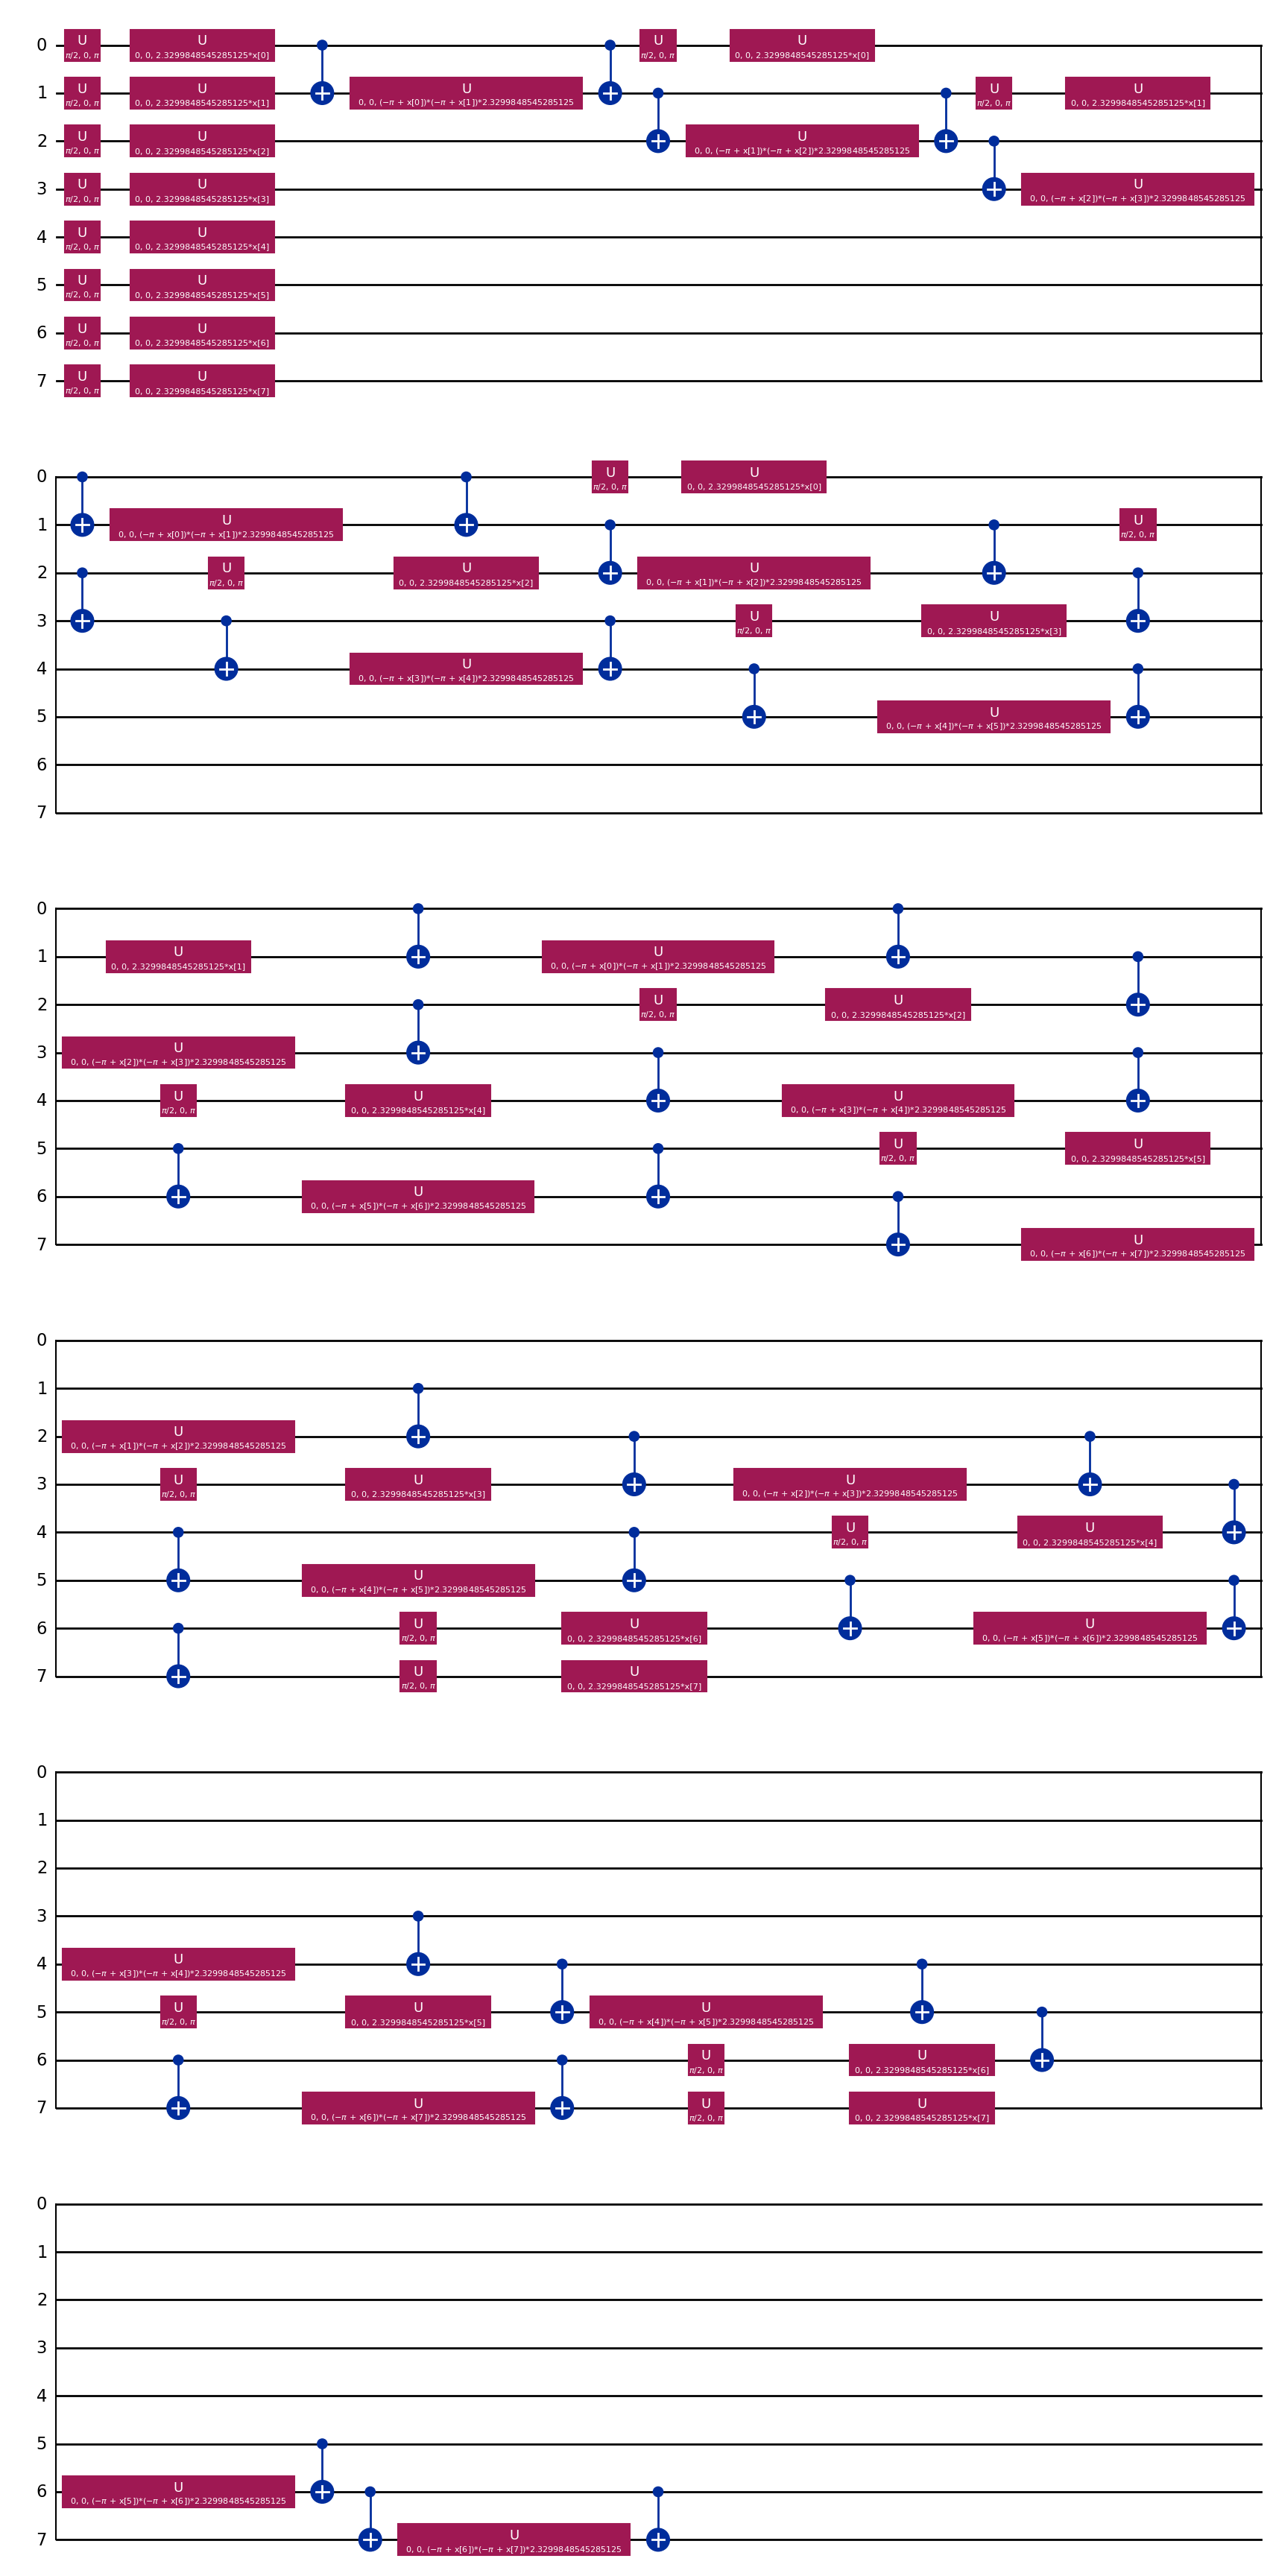

In [34]:
best_params = study.best_params

final_feature_map = zz_feature_map(
    feature_dimension = 8,
    reps = best_params["reps"],
    entanglement = "linear",
    alpha = best_params["alpha"]
)
print("reps:", best_params["reps"])
print("alpha:", best_params["alpha"])

final_feature_map.decompose().draw("mpl")

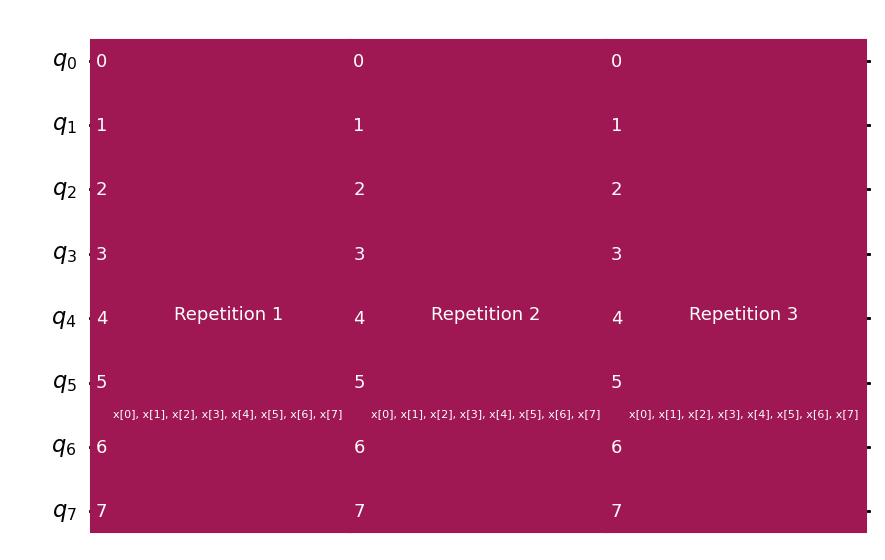

Repetition 1


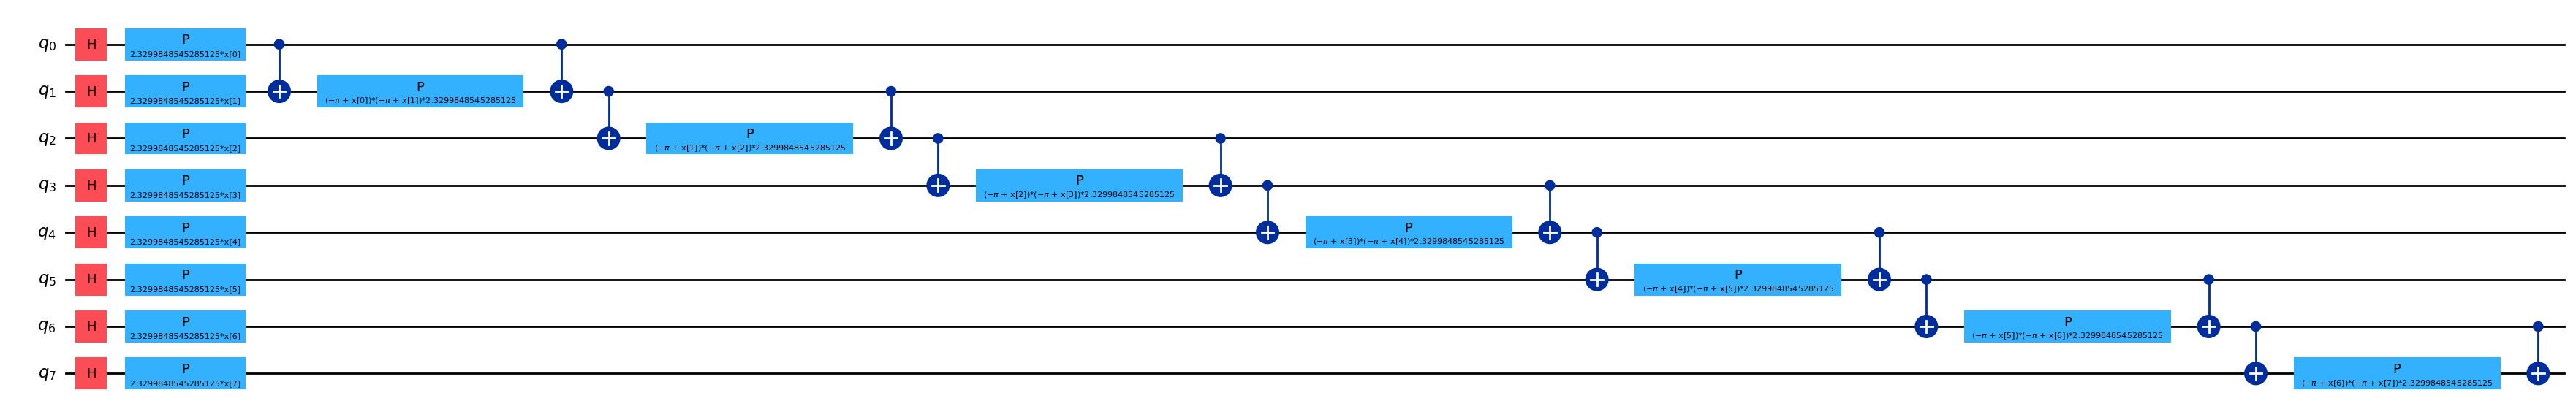

Repetition 2


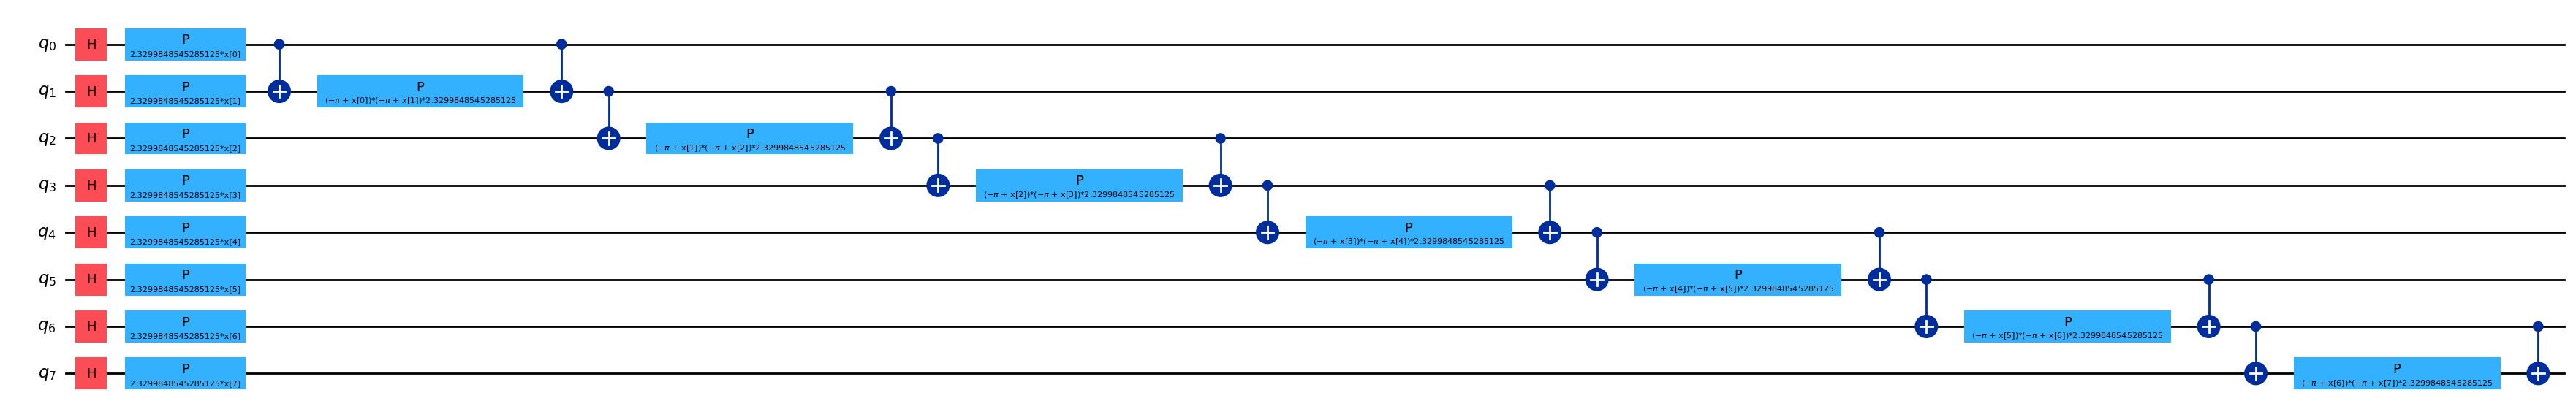

Repetition 3


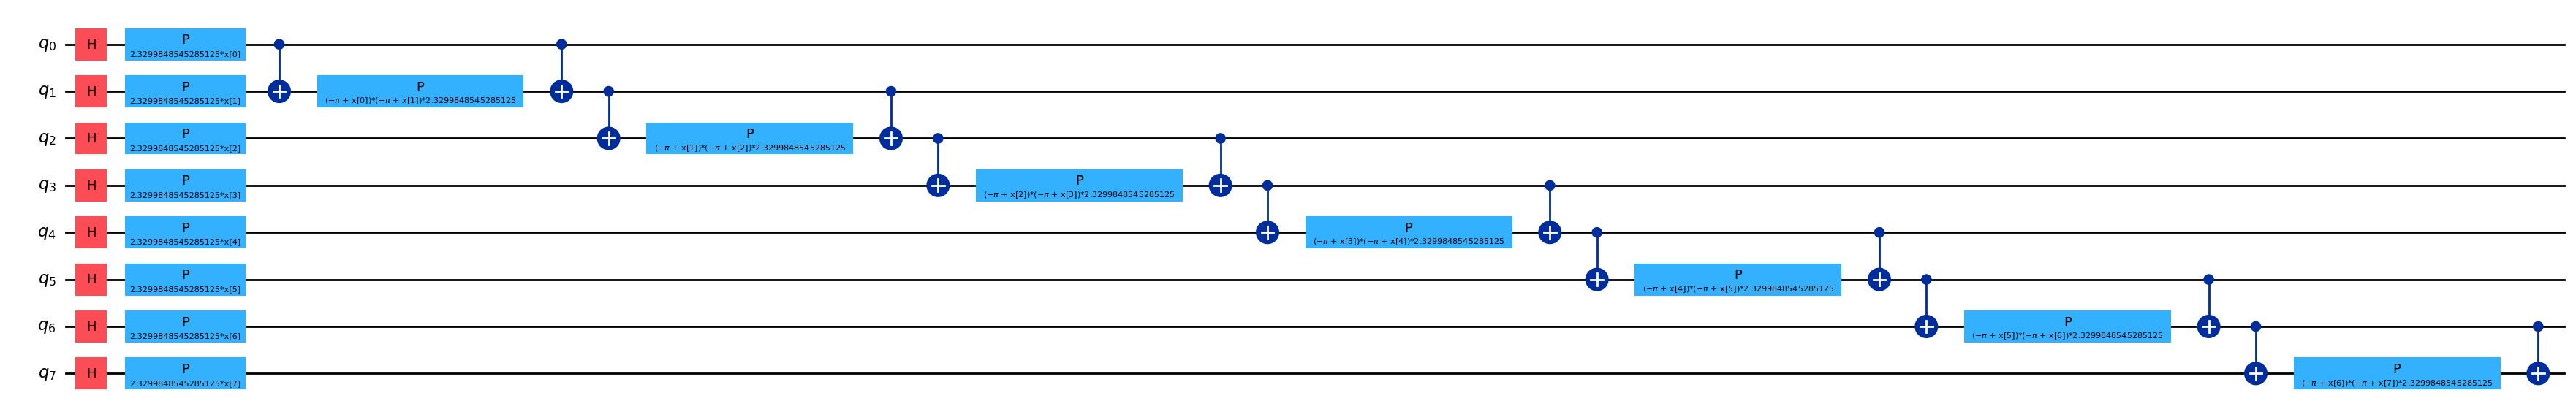

In [35]:
def encapsulate_repetitions(feature_map, reps):

    n_qubits = feature_map.num_qubits
    n_instructions = len(feature_map.data)

    # Verify that instructions can be divided evenly
    if n_instructions % reps != 0:
        raise ValueError(
            f"{n_instructions} instructions cannot be "
            f"divided evenly into {reps} repetitions."
        )

    instructions_per_rep = n_instructions // reps

    encapsulated_circuit = QuantumCircuit(n_qubits)

    # Preserve the original global phase
    encapsulated_circuit.global_phase = feature_map.global_phase

    for rep in range(reps):

        start = rep * instructions_per_rep
        end = (rep + 1) * instructions_per_rep

        # Create a subcircuit for this repetition
        rep_circuit = QuantumCircuit(
            n_qubits,
            name=f"Repetition_{rep + 1}"
        )

        # Copy the original instructions in their exact order
        for instruction in feature_map.data[start:end]:

            qargs = [
                rep_circuit.qubits[
                    feature_map.find_bit(q).index
                ]
                for q in instruction.qubits
            ]

            cargs = [
                rep_circuit.clbits[
                    feature_map.find_bit(c).index
                ]
                for c in instruction.clbits
            ]

            rep_circuit.append(
                instruction.operation,
                qargs,
                cargs
            )

        # Encapsulate the entire repetition
        rep_gate = rep_circuit.to_gate(
            label=f"Repetition {rep + 1}"
        )

        # Append as one composite operation
        encapsulated_circuit.append(
            rep_gate,
            encapsulated_circuit.qubits
        )

    return encapsulated_circuit


# Apply to your already-generated feature map
encapsulated_feature_map = encapsulate_repetitions(
    final_feature_map,
    best_params["reps"]
)

# Display
display(
    encapsulated_feature_map.draw(
        output="mpl",
        fold=-1
    )
)

for i, instruction in enumerate(encapsulated_feature_map.data):

    print(f"Repetition {i + 1}")

    display(
        instruction.operation.definition.draw(
            output="mpl",
            fold=-1
        )
    )

In [36]:
qc = final_feature_map.decompose()

print("Circuit width (qubits):", qc.num_qubits)
print("Circuit depth:", qc.depth())
print("Total gate count:", qc.size())
print("Gate counts:", qc.count_ops())

Circuit width (qubits): 8
Circuit depth: 39
Total gate count: 111
Gate counts: OrderedDict({'u': 69, 'cx': 42})


## 5. Analisis y construccion del Kernel


Se realizara un pequeño analisis del kernel obtenido despues de utilizar obtuna para tener los mejores hiperparametros para el QSVC, este analisis se realiza para entender el funcionamiento del kernel y si existe perdida o no de información al pasar el conjunto de entrenamiento por el kernel.

Maximum symmetry error: 0.0
Diagonal min/max: 1.0 / 1.0
Minimum eigenvalue: -1.100447219817231e-14
Number of significantly negative eigenvalues: 0


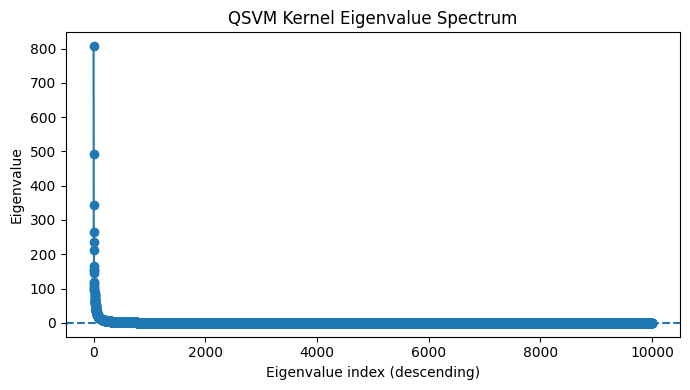

Number of samples: 10000
Largest eigenvalue: 806.832190172154
Smallest eigenvalue: -1.100447219817231e-14
Effective rank: 278.2988581665115
Effective rank ratio: 0.027829885816651148


In [37]:
best_kernel = FidelityStatevectorKernel(
    feature_map = final_feature_map,
    shots = None
)

start_kernel_train = time.perf_counter()
K_train_best = best_kernel.evaluate(x_vec=Xq_train, y_vec=Xq_train)
end_kernel_train = time.perf_counter()
kernel_training_time = (end_kernel_train - start_kernel_train)

# Symmetry error
symmetry_error = np.max(np.abs(K_train_best - K_train_best.T))

# Diagonal values
diagonal = np.diag(K_train_best)

# Eigenvalues of the symmetrized matrix
K_symmetric = (K_train_best + K_train_best.T) / 2
eigenvalues = np.linalg.eigvalsh(K_symmetric)

print("Maximum symmetry error:", symmetry_error)
print("Diagonal min/max:", diagonal.min(), "/", diagonal.max())
print("Minimum eigenvalue:", eigenvalues.min())
print("Number of significantly negative eigenvalues:", np.sum(eigenvalues < -1e-8))

K = np.asarray(K_train_best, dtype=float)
K = (K + K.T) / 2  # Remove tiny asymmetry from round-off

eigenvalues = np.linalg.eigvalsh(K)
eigenvalues = np.clip(eigenvalues, 0, None)

# Normalize eigenvalues to sum to 1
p = eigenvalues / eigenvalues.sum()
p_nonzero = p[p > 0]

effective_rank = np.exp(
    -np.sum(p_nonzero * np.log(p_nonzero))
)

n = len(eigenvalues)

plt.figure(figsize=(7, 4))
plt.plot(np.sort(eigenvalues)[::-1], marker="o")
plt.axhline(0, linestyle="--")
plt.xlabel("Eigenvalue index (descending)")
plt.ylabel("Eigenvalue")
plt.title("QSVM Kernel Eigenvalue Spectrum")
plt.tight_layout()
plt.show()

print("Number of samples:", n)
print("Largest eigenvalue:", eigenvalues[-1])
print("Smallest eigenvalue:", np.linalg.eigvalsh(K)[0])
print("Effective rank:", effective_rank)
print("Effective rank ratio:", effective_rank / n)

Se puede notar que la matriz generada por el kernel no posee errores de dimensionalidad ni en su diagonal, a su vez se nota que no existen valores propios (eigenvalues) significativos menores a 0, el minimo encontrado se puede atribuir a un error de redondeo ya que es demasiado pequeño para importar.

De los 10000 valores propios evaluados, podemos notar en la grafica que el mas alto tiene un valor de `806.832...` y representa aproximadamente `8.07%` de la suma total de los valores propios, disminuye rapidamente por cada valor propio hasta que decae a un numero cercano a cero, esto nos indica que existen direcciones espectrales con mayor peso a otras. A su vez como podemos notar del effective rank, se tiene un rango efectivo de `2.78%`, lo que indica que la masa espectral esta concentrada en un subconjunto pequeño de direcciones.

In [38]:
K = np.asarray(K_train_best)
y = np.asarray(y_train)

# Use each unique pair only once; exclude self-similarities.
i, j = np.triu_indices(len(y), k=1)

same = y[i] == y[j]
within = K[i[same], j[same]]
between = K[i[~same], j[~same]]

for name, values in [("Within", within), ("Between", between)]:
    print(
        f"{name}: mean={values.mean():.5f}, "
        f"median={np.median(values):.5f}, "
        f"90th percentile={np.percentile(values, 90):.5f}, "
        f"99th percentile={np.percentile(values, 99):.5f}"
    )

classes = np.unique(y)
rows = []

for a_idx, class_a in enumerate(classes):
    for class_b in classes[a_idx:]:
        mask = (
            (y[i] == class_a) & (y[j] == class_b)
        ) | (
            (y[i] == class_b) & (y[j] == class_a)
        )

        # For same-class pairs, only pairs where both labels equal class_a
        if class_a == class_b:
            mask = (y[i] == class_a) & (y[j] == class_a)

        values = K[i[mask], j[mask]]

        if len(values) > 0:
            rows.append({
                "Class A": class_a,
                "Class B": class_b,
                "Pair type": (
                    "Within class" if class_a == class_b
                    else "Between classes"
                ),
                "Mean similarity": values.mean(),
                "Median similarity": np.median(values),
                "Number of pairs": len(values)
            })

pair_results = pd.DataFrame(rows)
display(pair_results.sort_values("Mean similarity", ascending=False))

Within: mean=0.04299, median=0.00516, 90th percentile=0.05908, 99th percentile=0.83346
Between: mean=0.01274, median=0.00502, 90th percentile=0.02938, 99th percentile=0.11914


,Class A,Class B,Pair type,Mean similarity,Median similarity,Number of pairs
2,1,1,Within class,0.069620,0.011004,1425516
0,0,0,Within class,0.041890,0.005004,34532205
1,0,1,Between classes,0.012742,0.005017,14037279


Como podemos ver en el tabla, se definen las clases en 0 y 1, donde 0 es beningno y 1 es ataque, los resultados nos indican que existen una similitud media y promedio entre los pares de una misma clase que los pares entre diferentes clases, esto nos permite identificar que ahi una diferencia notable entre los valores dentro de una misma clase y los valores de dos clases diferentes, la diferencia es lo suficientemente considerable que incluso si usamos los percentiles de 90 y 99 se puede notar que existe muchisima mas similidad entre los valores de una misma clase comparados a los de diferentes clases.

Estos resultados nos permiten trabajar con confianza ya que incluso con la alta diferencia entre porcentaje de ataques y benignos en la data inicial, donde solo 16.9% de los datos son ataques, se puede distinguir diferencia entre las dos clases permitiendo entrenar el modelo sin que tienda a clasificar todo en un solo grupo o se confunda constantemente.

El resultado obtenido por la correlacion de spearman entre las distancias clasicas vs la similitud cuantica nos indica que existe una asociacion debil negativa entre ambos, esto sugiere que el kernel cuantico retiene parcialmente la estructura clasica de los datos aunque no reproduce las distanciasn entre muestras de manera perfecta.

##  6. Entrenamiento modelo final con los mejores hiperparametros

In [39]:
final_qsvm = SVC(kernel="precomputed", C=best_params["C"], class_weight="balanced", decision_function_shape="ovr", probability=False)
start_svm_train = time.perf_counter()
final_qsvm.fit(K_train_best, y_train)
end_svm_train = time.perf_counter()
svm_training_time = (end_svm_train - start_svm_train)

##  7. Evaluacion y analisis final en test

In [40]:
start_kernel_test = time.perf_counter()
K_test = best_kernel.evaluate(x_vec=Xq_test, y_vec=Xq_train)
end_kernel_test = time.perf_counter()
kernel_inference_time = (end_kernel_test - start_kernel_test)

start_prediction = time.perf_counter()
y_test_pred = final_qsvm.predict(K_test)
end_prediction = time.perf_counter()
prediction_time = (end_prediction - start_prediction)

y_test_score = final_qsvm.decision_function(K_test)

total_training_time = (kernel_training_time + svm_training_time)
total_inference_time = (kernel_inference_time + prediction_time)

print("Training Time")
print("-----------------------------")
print(f"Quantum kernel training: {kernel_training_time:.4f} s")
print(f"QSVM fitting:             {svm_training_time:.4f} s")
print(f"Total training time:     {total_training_time:.4f} s")

print("\nInference Time")
print("-----------------------------")
print(f"Quantum kernel inference: {kernel_inference_time:.4f} s")
print(f"QSVM prediction:           {prediction_time:.4f} s")
print(f"Total inference time:     {total_inference_time:.4f} s")


print("\nPrediction Results")
print("-----------------------------")
print("Macro F1:", f1_score(y_test, y_test_pred, average="macro"))
print("Balanced accuracy:", balanced_accuracy_score(y_test, y_test_pred))

print("\nClassification report:")
print(classification_report(y_test, y_test_pred, digits=4, target_names=["Benigno (0)", "Ataque (1)"]))

Training Time
-----------------------------
Quantum kernel training: 887.6053 s
QSVM fitting:             0.2321 s
Total training time:     887.8374 s

Inference Time
-----------------------------
Quantum kernel inference: 147.7911 s
QSVM prediction:           0.0193 s
Total inference time:     147.8104 s

Prediction Results
-----------------------------
Macro F1: 0.9893192062034051
Balanced accuracy: 0.9893192062034051

Classification report:
              precision    recall  f1-score   support

 Benigno (0)     0.9964    0.9964    0.9964       831
  Ataque (1)     0.9822    0.9822    0.9822       169

    accuracy                         0.9940      1000
   macro avg     0.9893    0.9893    0.9893      1000
weighted avg     0.9940    0.9940    0.9940      1000



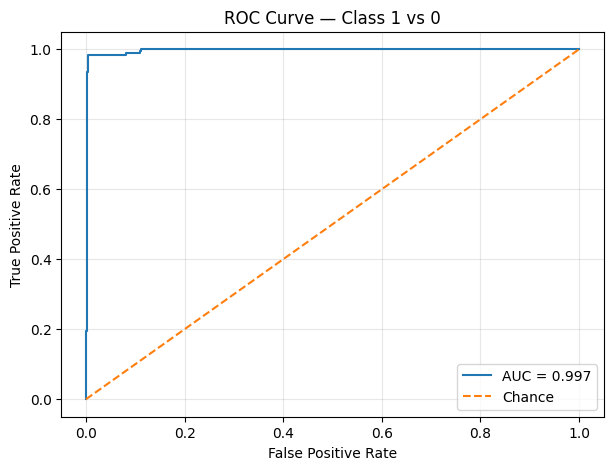

In [41]:
classes = np.unique(y_train)

# Binary SVC decision_function gives a single score
positive_scores = y_test_score if y_test_score.ndim == 1 else y_test_score[:, 1]

fpr, tpr, _ = roc_curve(y_test, positive_scores, pos_label=classes[1])
auc_value = roc_auc_score(y_test, positive_scores)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"AUC = {auc_value:.3f}")
plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve — Class {classes[1]} vs {classes[0]}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

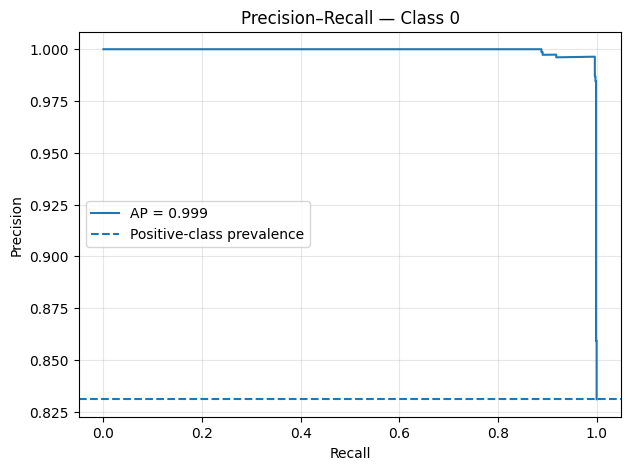

In [42]:
positive_scores = -y_test_score
    
precision, recall, _ = precision_recall_curve(y_test, positive_scores, pos_label=classes[0])
ap = average_precision_score(y_test, positive_scores, pos_label=classes[0])

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"AP = {ap:.3f}")
plt.axhline(np.mean(np.asarray(y_test) == classes[0]), linestyle="--", label="Positive-class prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall — Class {classes[0]}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

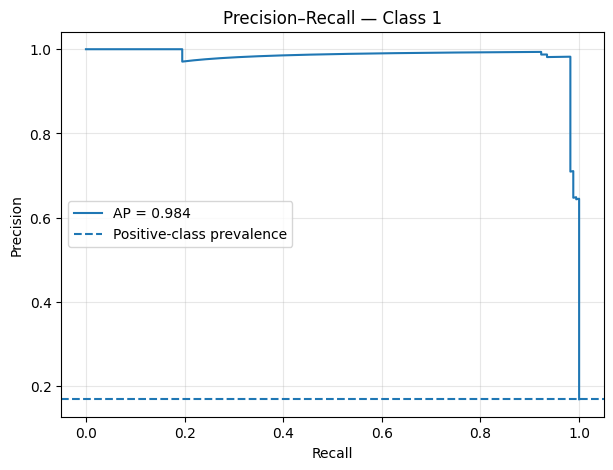

In [43]:
positive_scores = y_test_score

precision, recall, _ = precision_recall_curve(y_test, positive_scores, pos_label=classes[1])
ap = average_precision_score(y_test, positive_scores, pos_label=classes[1])

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"AP = {ap:.3f}")
plt.axhline(np.mean(np.asarray(y_test) == classes[1]), linestyle="--", label="Positive-class prevalence")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall — Class {classes[1]}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/calibration.py:333: UserWarning:

The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.



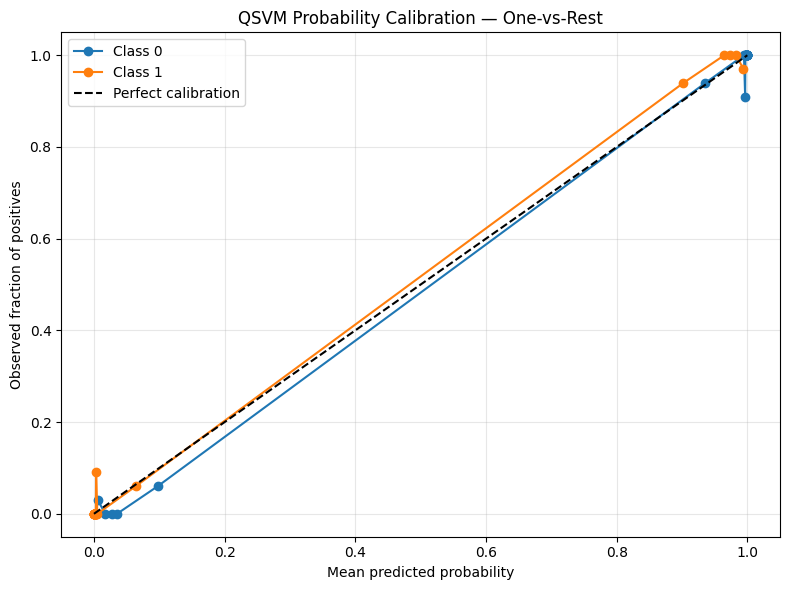


========== QSVM Calibration Metrics ==========

Class 0:
  ECE   : 0.008849
  MCE   : 0.087582
  Brier : 0.006930

Class 1:
  ECE   : 0.008849
  MCE   : 0.087582
  Brier : 0.006930

Overall Multiclass Brier Score:
  0.013860


In [44]:
K_val = best_kernel.evaluate(Xq_val, Xq_train)

calibrated_svc = CalibratedClassifierCV(
    estimator=final_qsvm,
    method="sigmoid",
    cv="prefit"
)

calibrated_svc.fit(K_val, y_val)

y_proba = calibrated_svc.predict_proba(K_test)

classes = final_qsvm.classes_
y_test_array = np.asarray(y_test)

def calibration_metrics(y_true, y_prob, n_bins=30):

    bin_edges = np.quantile(y_prob, np.linspace(0, 1, n_bins + 1))
    bin_edges = np.unique(bin_edges)
    bin_indices = np.digitize(y_prob, bin_edges[1:-1], right=True)

    ece = 0.0
    mce = 0.0

    for bin_idx in np.unique(bin_indices):

        mask = bin_indices == bin_idx

        if np.sum(mask) == 0:
            continue

        mean_confidence = np.mean(y_prob[mask])
        mean_accuracy = np.mean(y_true[mask])
        error = abs(mean_accuracy - mean_confidence)
        
        ece += (np.sum(mask) / len(y_prob)) * error
        mce = max(mce, error)

    brier = brier_score_loss(y_true, y_prob)

    return ece, mce, brier

class_metrics = {}
plt.figure(figsize=(8, 6))

for i, cls in enumerate(classes):

    y_binary = (y_test_array == cls).astype(int)

    probabilities = y_proba[:, i]

    ece, mce, brier = calibration_metrics(
        y_binary,
        probabilities,
        n_bins=30
    )

    class_metrics[cls] = {
        "ECE": ece,
        "MCE": mce,
        "Brier": brier
    }

    prob_true, prob_pred = calibration_curve(
        y_binary,
        probabilities,
        n_bins=30,
        strategy="quantile"
    )

    plt.plot(
        prob_pred,
        prob_true,
        marker="o",
        label=f"Class {cls}"
    )

y_onehot = np.column_stack([
    (y_test_array == cls).astype(int)
    for cls in classes
])

multiclass_brier = np.mean(
    np.sum((y_proba - y_onehot) ** 2, axis=1)
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction of positives")

plt.title(
    "QSVM Probability Calibration — One-vs-Rest"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n========== QSVM Calibration Metrics ==========")

for cls, metrics in class_metrics.items():

    print(f"\nClass {cls}:")
    print(f"  ECE   : {metrics['ECE']:.6f}")
    print(f"  MCE   : {metrics['MCE']:.6f}")
    print(f"  Brier : {metrics['Brier']:.6f}")

print("\nOverall Multiclass Brier Score:")
print(f"  {multiclass_brier:.6f}")

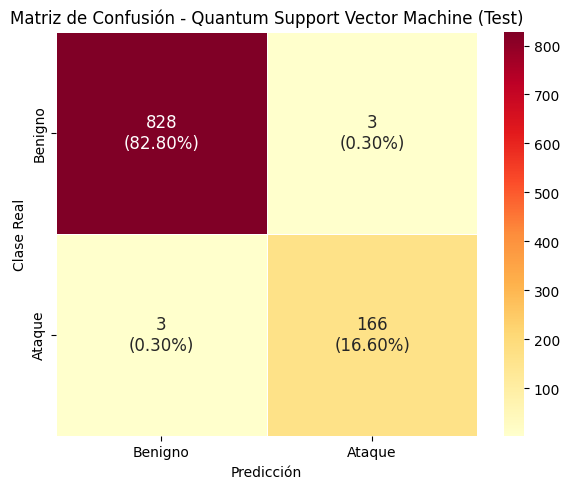

In [45]:
cm_qsvm = confusion_matrix(y_test, y_test_pred)

tn, fp, fn, tp = cm_qsvm.ravel()
total = cm_qsvm.sum()
tp_percent = (tp / total) * 100
fp_percent = (fp / total) * 100
tn_percent = (tn / total) * 100
fn_percent = (fn / total) * 100

labels = [
    [f"{cm_qsvm[0,0]}\n({tn_percent:.2f}%)", f"{cm_qsvm[0,1]}\n({fp_percent:.2f}%)"],
    [f"{cm_qsvm[1,0]}\n({fn_percent:.2f}%)", f"{cm_qsvm[1,1]}\n({tp_percent:.2f}%)"]
]

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_qsvm,
    annot=labels,
    fmt="",
    cmap="YlOrRd",
    linewidths=0.5,
    annot_kws={"size": 12},
    xticklabels=["Benigno", "Ataque"],
    yticklabels=["Benigno", "Ataque"]
)
plt.title("Matriz de Confusión - Quantum Support Vector Machine (Test)")
plt.xlabel("Predicción")
plt.ylabel("Clase Real")
plt.tight_layout()
plt.show()

##  8. Reporte del QSVM

### Análisis de resultados de Optuna

Debido a que el tiempo de entrenamiento para cada trial toma alrededor de 20 minutos, se definio una cantidad de trials de solo 10, para obtener resultados mas exactos y mejores se tendra que hacer uso de una mayor cantidad de trials y de ser posible con mas valores de train y validación.

#### Optimization History Plot

Este grafico muestra una comparacion entre los valores objetivo obtenidos en cada trial `designado por puntos azules` y el mejor valor obtenido a lo largo de los trials `indicado por una linea roja`, esta grafica nos permite analizar y entender el comportamiento que se tuvo durante la busqueda de hiperparametros y los resultados totales obtenidos por trial.

#### Hyperparameter Importances

La grafica muestra cuales hiperparametros tuvieron la mayor significacia a la hora de afectar los resultados por cada trial, como podemos ver en el grafico los hiperparametros con mayor significancia son `C` y `alpha` ya que estos son los que generan las fluctuaciones de resultados mas identificables comparado al otro hiperparametro.

#### Parallel Coordinate Plot

El grafico muestra como diferentes agrupamientos de hiperparametros generan los valores objetivos obtenidos, se puede notar que el valor de `C` suele generar los cambios mas altos, ya que un `C alto` genera un alto valor objetivo, mientras que un `C bajo` aproximado a 0, genera que los resultados decaigan demasiado y se generen resultados muy alejados de los esperados. Se puede notar un similar efecto con el hiperparametro `alpha`.

#### Conclusion de los graficos

Debido a los altos cambios generados por `C` y `alpha`, se consideran ambos hiperparametros altamente importantes a la hora de evaluar los resultados de los modelos, se debe tener en cuenta a su vez que un `C` muy alto generara problemas de overfitting, asi que se tendra en cuenta si se obtiene un `C` muy alto a la hora de realizar las pruebas de optuna para tener un buen balance de hiperparametros.


### Feature map obtenido y ancho y profundidad del circuito cuantico.

En el diagrama obtenido del feature map, podemos ver que se tienen 8 lineas, una linea por cada qubit usado en el feature map, dandonos un `ancho de 8` para nuestro modelo cuantico actual, y la profundidad esta definida por la cantidad de compuertas `U` que se encuentran en el grafico, tenemos inicialmente en cada qubit 2 puertas U por qubit y despues de ellas, 7 puertas U mas conectadas a travez de `compuertas CX`, esto se repite 1 vez mas por cada repeticion extra, en nuestro caso teniendo 3 repeticiones y teniendo 21 compuestas `U` conectadas por compuertas CX, esto nos da un total de una `profundidad igual a 39`


### Interpretacion de las graficas:
Evaluando sobre el conjunto de prueba independiente (`Test` con 1,000 muestras), se realizaron las siguientes graficas para evaluar los resultados:


#### ROC - AUC
Se evalua que tan bien nuestro modelo es capaz de distinguir entre las dos clases, en nuestro caso la clase 0, benigno y la clase 1, ataque. Como se nota en el grafico nuestra linea que delimita la tasa de verdaderos positivos contra falsos positivos se encuentra bastante por encima de una clasificacion al azar de 50/50, y se posee un alto indice de AUC igual a `0.997` gracias a que ahi una gran area bajo la curva del area medida.


#### Graficos de Precision vs Recall
Este grafico nos permite verificar el desbalance de las clases y que tan bien o mal responde nuestro modelo a estas, como se puede notar en ambos graficos de precision vs recall, el modelo responde bastante bien a ambos, manteniendose bastante cercano a `1.0` durante casi todo el recorrido, indicando que el modelo identifica negativos y positivos con muy pocos errores en un buen rango de recall.

La precision promedio (AP) obtenida durante el recorrido nos permite verificar que tan bien responde la precision a diferentes niveles de recall, ya que esta muy cercana a 1.0 se considera que se tiene un rendimiento bastante bueno en ese apartado, en nuestro caso un AP de `0.999` para los benignos y un `0.984` para los ataques, se considera como muy buenos resultados, considerando el desbalance de clases inicial.


#### Calibracion de modelos
Permite evaluar el sesgo asumido por el modelo, en este caso comparando las probabilidades predichas para cada clase con la frecuencia real de esa clase, en la grafica podemos notar que ambas clases se aproximan muy de cerca a los puntos de calibracion perfecta, que es la linea negra.

Los valores obtenidos por ECE (Expected Calibration Error), MCE (Maximum Calibration Error) y puntaje de Brier, son similares tanto para la clase 0 como para la clase 1, esto se debe a que son clases binarias, donde una de las dos debe de ocurrir, por esto sus resultados para los valores obtenidos son iguales. 

Los valores obtenidos para el ECE es de `0.008849`, lo que nos indica que el error de calibracion promedio es bastante bajo, indicandonos que las probabilidades predecidas concuerdan con las frequencias observadas. 

El MCE obtenido es de `0.087582` lo que nos indica que aunque el error promedio es considerablemente bajo, existe un bin que presenta discrepancia significativa de calibracion.

Los valores obtenidos por el puntaje de Brier de `0.006930` y multiclass Brier de `0.013860` que es la suma de ambos puntajes de Brier, ambos valores son bastantes bajos, permitiendonos garantizar que la calidad de prediccion es bastante alta, ya que no existe un error significativo entre los resultados predecidos y los reales.

Usando los resultados obtenidos del modelo y los valores de ECE, MCE y Brier Score se puede concluir que no existe un sesgo claro para ninguna de las dos clases y el modelo mantiene un buen balance entre seguridad y predicciones correctas, mientras mantiene unas probabilidades bien calibradas.


### Interpretación de la Matriz de Confusión
Al revisar los resultados exactos de predicciones sobre las 1,000 muestras de prueba:
* **Falsos Positivos (FP):** De 831 conexiones benignas reales, el modelo solo clasificó erróneamente 4 como ataques.
* **Falsos Negativos (FN):** De 169 ataques reales, el modelo únicamente dejó pasar 6 como tráfico normal.

En total, el algoritmo solo cometió **10 errores sobre 1,000 registros**, lo que representa una tasa global de error de apenas el **1%** o **0.01**. Esto podemos notarlo en el *Precision* y *Recall*, ya que ambos tienen un valor pesado de 0.99, lo que indica que solo un 0.01 de los datos fue clasificado de manera erronea.


### Conclusión
El modelo Quantum Support Vector Machine demuestra unos resultados de buena calidad para la cantidad de datos suministrados para el entrenamiento y verificación, obteniendo valores mejores que los obtenidos por el modelo de SVM con kernel RBF, esto permitiendonos obtener un modelo que es muy competitivo con los clasicos mientras se usa una cantidad baja de datos para ambos modelos.